# Supplementary material

Double-panel figure:
- **(a)** Niño 1+2 SST anomaly (0°–10°S, 90°–80°W), from `ElNino_Nino12_timeseries.ipynb`
- **(b)** Amplitude of the drivers in the 111 km coastal band (16°S–5°S), from `v2.UI_comparison_paper_ENfix.ipynb` → *Amplitude of drivers*

The two extreme El Niño events (1982-06 → 1983-12 and 1997-04 → 1998-07) are shaded in both panels.

In [1]:
import os
import datetime
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.backends.backend_pdf import PdfPages

mask_km = 111
lat1, lat0 = -16, -5

NINO = [
    (datetime.datetime(1982, 6, 1), datetime.datetime(1983, 12, 31)),
    (datetime.datetime(1997, 4, 1), datetime.datetime(1998, 7, 31)),
]

## Helpers

In [2]:
def coastal_band_mask(ds, var='u10', target_width_km=111):
    """
    Create a coastal band mask with uniform cross-shore width in km.
    """
    da = ds[var]
    if 'time' in da.dims:
        da = da.mean(dim='time')

    valid2d = np.isfinite(da).values.astype(bool)
    lat_vals = ds['lat'].values
    lon_vals = ds['lon'].values
    dlon = np.abs(lon_vals[1] - lon_vals[0])  # grid spacing in degrees

    # Find coastline (easternmost valid cell per row)
    band = np.zeros_like(valid2d, dtype=bool)

    for j in range(valid2d.shape[0]):
        row = valid2d[j, :]
        ocean_cols = np.where(row)[0]
        if len(ocean_cols) == 0:
            continue

        # Coast = easternmost valid cell
        i_coast = ocean_cols[-1]

        # How many cells = target_width_km at this latitude?
        A = 6371.0  # km
        dx_km = A * np.cos(np.deg2rad(lat_vals[j])) * np.deg2rad(dlon)
        n_cells = int(np.round(target_width_km / dx_km))

        # Fill n_cells westward from coast
        i_start = max(i_coast - n_cells, 0)
        band[j, i_start:i_coast + 1] = True

    # Only keep cells that are actually ocean
    band = band & valid2d

    da_mask = xr.DataArray(band, dims=('lat', 'lon'),
                           coords={'lat': ds['lat'], 'lon': ds['lon']})
    return da_mask


def prep_for_taylor(da, dim='time', window=13):
    """Climatology removal → 13-month running mean → drop NaNs."""
    clim = da.groupby(f'{dim}.month').mean(dim=dim)
    anom = da.groupby(f'{dim}.month') - clim
    return anom.rolling({dim: window}, center=True).mean().dropna(dim=dim)


def make_patch_spines_invisible(ax):
    ax.set_frame_on(True)
    ax.patch.set_visible(False)
    for sp in ax.spines.values():
        sp.set_visible(False)

## (a) Niño 1+2 SST anomaly

Monthly anomaly and its 3-month moving average. El Niño (La Niña): 3-month anomaly > +0.5 °C (< −0.5 °C).

In [3]:
THRESHOLD = 0.5

ds = xr.open_dataset('../data/SST.nc')
sst = ds.SST.where(ds.SST != 0, np.nan)

sst_ts = sst.sel(lat=slice(-10, 0), lon=slice(-90, -80)).mean(dim=('lat', 'lon'))
clim = sst_ts.groupby('time.month').mean('time')
anom = sst_ts.groupby('time.month') - clim
anom_3mo = anom.rolling(time=3, center=True).mean()

## (b) Amplitude of drivers

Coastal band of 111 km, 16°S–5°S. Anomalies relative to the monthly climatology, 13-month running mean, El Niño **kept**.

In [4]:
# SSH, MLD over the coastal band (SST file only used to build the mask)
SST = xr.open_dataset('../data/SST.nc').compute()
SST = SST.where(SST.SST != 0, np.nan)
mask = coastal_band_mask(SST, 'SST', mask_km).sel(lon=slice(-85, None), lat=slice(lat1, lat0))

SSH = xr.open_dataset('../data/SSH.nc').compute()
SSH = SSH.where(SSH.SSH != 0, np.nan)
SSH = SSH.where(mask).SSH
SSHs = prep_for_taylor(SSH.mean(dim=('lat', 'lon')))

MLD = xr.open_dataset('../data/MLD.nc').compute()
MLD = MLD.where(mask).MLD
MLDs = prep_for_taylor(MLD.mean(dim=('lat', 'lon')))

In [6]:
# U_GEO and U_Ek from the high-resolution CUTI file (stored N -> S, sort S -> N)
# U_ek = Ek_t (~111 km) + meridional Ekman fluxes on the row faces (v1 method)
hr = xr.open_dataset('../data/CUTI_BEUTI_HR_L.nc').sortby('lat_band').compute().sel(lat_band=slice(lat1, lat0))
UGEOs = prep_for_taylor(hr.UGEO.mean(dim='lat_band'))
UEKs  = prep_for_taylor(hr.U_ek.mean(dim='lat_band'))

## Double-panel figure

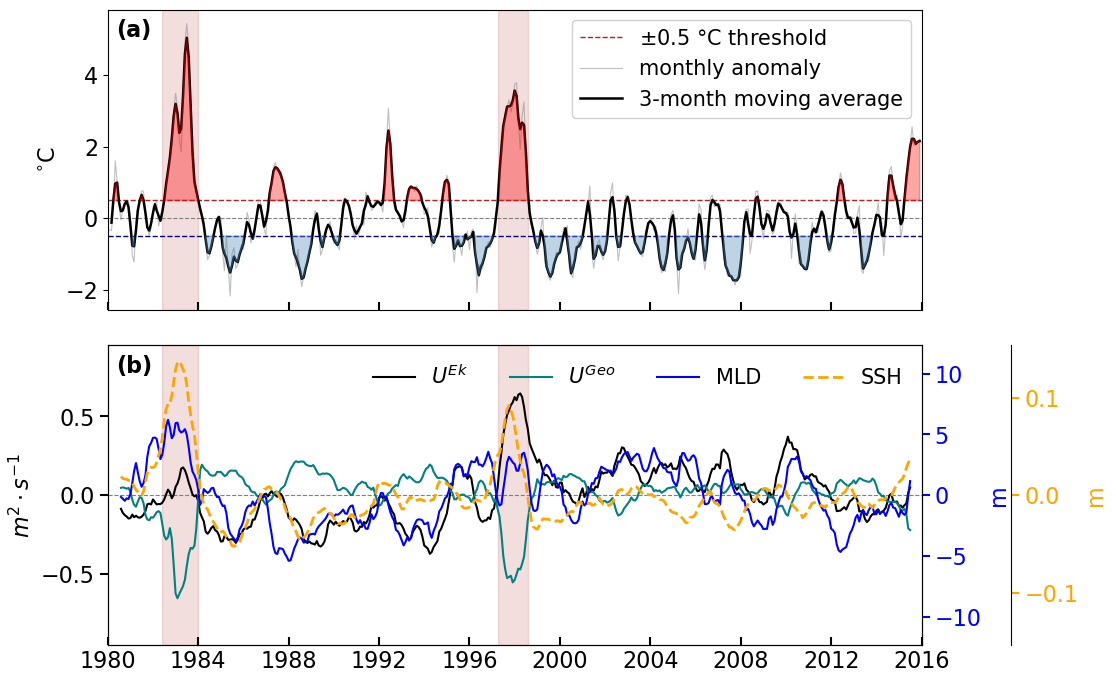

In [ ]:
lp = 4
k = 5  # y-limits = ±k std of each series

fig, (axa, host) = plt.subplots(2, 1, figsize=(14*0.75, 11*0.75), sharex=True,
                                gridspec_kw=dict(height_ratios=[1, 1], hspace=0.12))

# ============================================================
# (a) Niño 1+2 SST anomaly
# ============================================================
t = anom_3mo.time.values
axa.axhline(0.0, color='grey', linestyle='--', lw=0.8, zorder=1)
axa.axhline(THRESHOLD, color='firebrick', lw=1.0, ls='--', zorder=1,
            label=f'$\\pm${THRESHOLD} °C threshold')
axa.axhline(-THRESHOLD, color='navy', lw=1.0, ls='--', zorder=1)

axa.plot(anom.time.values, anom.values, color='grey', lw=0.8, alpha=0.5,
         label='monthly anomaly')
axa.plot(t, anom_3mo.values, color='black', lw=1.8,
         label='3-month moving average')

axa.fill_between(t, THRESHOLD, anom_3mo.values, where=anom_3mo.values > THRESHOLD,
                 color='red', alpha=0.35, zorder=2)
axa.fill_between(t, -THRESHOLD, anom_3mo.values, where=anom_3mo.values < -THRESHOLD,
                 color='steelblue', alpha=0.35, zorder=2)

axa.set_ylabel(r'$^{\circ}$C', fontsize=16)
# axa.set_title('Niño 1+2 SST anomaly (0°–10°S, 90°–80°W)', fontsize=16)
axa.tick_params(axis='both', which='major', labelsize=16)
axa.legend(loc='upper right', fontsize=15, framealpha=0.9)

# ============================================================
# (b) Amplitude of drivers
# ============================================================
par1 = host.twinx()
par2 = host.twinx()

par2.spines['right'].set_position(('axes', 1.11))
make_patch_spines_invisible(par2)
par2.spines['right'].set_visible(True)

# U_Ek and U_GEO share the host axis (both m^2 s^-1), so their cancellation is visible directly
p1, = host.plot(UEKs.time,  UEKs,  lw=1.5, color='black',  label=r'$U^{Ek}$')
p2, = host.plot(UGEOs.time, UGEOs, lw=1.5, color='teal', label=r'$U^{Geo}$')
p3, = par1.plot(MLDs.time,  MLDs,  lw=1.5, color='blue',   label='MLD')
p4, = par2.plot(SSHs.time,  SSHs,  lw=2, color='orange',   linestyle='--', label='SSH')
host.axhline(0, color='grey', linestyle='--', lw=0.8, zorder=1)

sd_u = max(UEKs.std().item(), UGEOs.std().item())
host.set_ylim(-k * sd_u,                 k * sd_u)
par1.set_ylim(-k * MLDs.std().item(),    k * MLDs.std().item())
par2.set_ylim(-k * SSHs.std().item(),    k * SSHs.std().item())

host.set_ylabel(r'$m^{2} \cdot s^{-1}$', fontsize=16, labelpad=lp)
par1.set_ylabel('m', fontsize=16, labelpad=lp)
par2.set_ylabel('m', fontsize=16, labelpad=lp)

tkw = dict(size=6, width=1.5)
for ax, col in zip((host, par1, par2), ('black', 'blue', 'orange')):
    ax.yaxis.label.set_color(col)
    ax.tick_params(axis='y', colors=col, labelsize=16, **tkw)
for ax in (axa, host):
    ax.tick_params(axis='x', direction='in', labelsize=16, **tkw)

host.legend([p1, p2, p3, p4], [h.get_label() for h in (p1, p2, p3, p4)],
            fontsize=15, loc='upper right', bbox_to_anchor=(1.0, 1.0), frameon=False, ncol=4)
host.set_axisbelow(True)
# host.set_title('Ocean state (1980–2015)', fontsize=16)

# ============================================================
# Shared: El Niño shading, x-axis, panel labels
# ============================================================
for ax in (axa, host):
    for start, end in NINO:
        ax.axvspan(start, end, facecolor='firebrick', edgecolor='firebrick', alpha=0.15, zorder=0)

host.set_xlim(datetime.datetime(1980, 1, 1), datetime.datetime(2016, 1, 1))
host.xaxis.set_major_locator(mdates.YearLocator(4))
host.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

for ax, lab in zip((axa, host), ('(a)', '(b)')):
    ax.text(0.01, 0.97, lab, transform=ax.transAxes, fontsize=16,
            fontweight='bold', va='top', ha='left')

# fig.subplots_adjust(right=0.85)

os.makedirs('Figures', exist_ok=True)
# with PdfPages('Figures/Appendix_A.pdf') as pdf:
#     pdf.savefig(fig, bbox_inches='tight')
plt.show()

## Numbers quoted in the text

Each driver is averaged over the 111 km coastal band (16°S–5°S), as in panel (b). For each El Niño event:
- **event-mean anom.**: mean of the deseasonalised, unsmoothed monthly anomaly over the event, the same method as the W_MLD / τ / MLD percentages in `v2.UI_comparison_paper_ENfix`
- **% of clim.**: event-mean anomaly as a percentage of the climatological mean (non-El Niño months)
- **peak (13-mo)**: largest-magnitude value of the 13-month smoothed anomaly (the curve in panel b) during the event
- **peak / σ**: that peak in standard deviations of the smoothed series. `σ_all` uses the full record (as in the panel's ±5σ y-limits); `σ_noEN` excludes the two events (typical interannual variability)

In [ ]:
def drop_en_events(da, en_windows=NINO, dim='time'):
    """Mask out El Niño periods from a time series."""
    keep = np.ones(da.sizes[dim], dtype=bool)
    time = da[dim].values
    for start, end in en_windows:
        keep &= ~((time >= np.datetime64(start)) & (time <= np.datetime64(end)))
    return da.isel({dim: keep})


# W_MLD (CROCO), same coastal band, in m^2 s^-1
wmld = xr.open_dataset('../W_mld_Croco.nc').compute()
wmld = wmld.where(coastal_band_mask(wmld, 'WMLD', mask_km)).sel(lon=slice(-85, None), lat=slice(lat1, lat0))

drivers = {
    'W_MLD (m2 s-1)':  (wmld.WMLD * 111 * 1000).mean(dim=('lat', 'lon')),
    'U_Ek (m2 s-1)':   hr.U_ek.mean(dim='lat_band'),
    'U_GEO (m2 s-1)':  hr.UGEO.mean(dim='lat_band'),
    'SST (degC)':      SST.SST.where(mask).mean(dim=('lat', 'lon')),
    'SSH (m)':         SSH.mean(dim=('lat', 'lon')),
    'MLD (m)':         MLD.mean(dim=('lat', 'lon')),
}
EVENTS = {'EN 1982-83': NINO[0], 'EN 1997-98': NINO[1]}

for label, da in drivers.items():
    clim = da.groupby('time.month').mean('time')
    anom = da.groupby('time.month') - clim
    base = float(drop_en_events(da).mean())
    smooth = prep_for_taylor(da)
    sd_all = float(smooth.std())
    sd_ne  = float(drop_en_events(smooth).std())
    print(f'{label}   clim. mean = {base:+.4f}   σ_all = {sd_all:.4f}   σ_noEN = {sd_ne:.4f}')
    for name, (t0, t1) in EVENTS.items():
        a  = float(anom.sel(time=slice(t0, t1)).mean())
        ev = smooth.sel(time=slice(t0, t1))
        pk = float(ev.values[np.argmax(np.abs(ev.values))])
        print(f'    {name}:  event-mean anom. {a:+.4f} ({100 * a / abs(base):+.0f}% of clim.)'
              f'   peak (13-mo) {pk:+.4f}  =  {pk / sd_all:+.1f} σ_all  /  {pk / sd_ne:+.1f} σ_noEN')
    print()


W_MLD (m2 s-1)   clim. mean = +1.8149   σ_all = 0.2578   σ_noEN = 0.2558
    EN 1982-83:  event-mean anom. -0.3144 (-17% of clim.)   peak (13-mo) -0.4648  =  -1.8 σ_all  /  -1.8 σ_noEN
    EN 1997-98:  event-mean anom. +0.1573 (+9% of clim.)   peak (13-mo) +0.5211  =  +2.0 σ_all  /  +2.0 σ_noEN

U_Ek (m2 s-1)   clim. mean = +2.1073   σ_all = 0.2208   σ_noEN = 0.1909
    EN 1982-83:  event-mean anom. +0.0606 (+3% of clim.)   peak (13-mo) +0.2167  =  +1.0 σ_all  /  +1.1 σ_noEN
    EN 1997-98:  event-mean anom. +0.6341 (+30% of clim.)   peak (13-mo) +0.7558  =  +3.4 σ_all  /  +4.0 σ_noEN

U_GEO (m2 s-1)   clim. mean = -0.2173   σ_all = 0.1150   σ_noEN = 0.0589
    EN 1982-83:  event-mean anom. -0.2945 (-136% of clim.)   peak (13-mo) -0.5204  =  -4.5 σ_all  /  -8.8 σ_noEN
    EN 1997-98:  event-mean anom. -0.3160 (-145% of clim.)   peak (13-mo) -0.4195  =  -3.6 σ_all  /  -7.1 σ_noEN

SST (degC)   clim. mean = +18.7569   σ_all = 0.9408   σ_noEN = 0.5369
    EN 1982-83:  event-mean anom. +2.

### Why is the 1997–98 mean U_GEO anomaly larger than 1982–83, although its peak is smaller?

Month-by-month deseasonalised (unsmoothed) U_GEO anomaly in each event window.

In [ ]:
ug = hr.UGEO.mean(dim='lat_band')
ug_anom = ug.groupby('time.month') - ug.groupby('time.month').mean('time')

for name, (t0, t1) in EVENTS.items():
    ev = ug_anom.sel(time=slice(t0, t1))
    v = ev.values
    print(f'{name}  (n = {v.size} months)   mean = {v.mean():+.3f}   median = {np.median(v):+.3f}'
          f'   min = {v.min():+.3f}   months < -0.2: {(v < -0.2).sum()}')
    print('   ' + '  '.join(f'{str(t)[:7]} {x:+.2f}' for t, x in zip(ev.time.values, v)))
    print()


EN 1982-83  (n = 19 months)   mean = -0.295   median = -0.101   min = -1.797   months < -0.2: 7
   1982-06 +0.03  1982-07 -0.10  1982-08 -0.12  1982-09 -0.05  1982-10 -0.13  1982-11 -0.66  1982-12 -0.66  1983-01 -0.23  1983-02 -0.03  1983-03 -0.06  1983-04 -0.95  1983-05 -1.80  1983-06 -1.72  1983-07 -0.25  1983-08 +0.24  1983-09 +0.19  1983-10 +0.20  1983-11 +0.29  1983-12 +0.21

EN 1997-98  (n = 16 months)   mean = -0.316   median = -0.289   min = -1.243   months < -0.2: 9
   1997-04 -0.05  1997-05 +0.00  1997-06 -0.17  1997-07 -0.31  1997-08 +0.15  1997-09 -0.37  1997-10 -0.26  1997-11 -0.97  1997-12 -1.24  1998-01 -0.75  1998-02 -0.59  1998-03 -0.12  1998-04 -0.37  1998-05 -0.45  1998-06 +0.22  1998-07 +0.22

